# 23 · Large Language Models, Alignment, Retrieval and Multimodal Models

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anuxlab/deep-learning-systems/blob/main/notebooks/23-llm-multimodal/23_llm_multimodal.ipynb)
[![Run on GitHub Actions](https://img.shields.io/badge/run-GitHub%20Actions-2088FF?logo=githubactions&logoColor=white)](https://github.com/anuxlab/deep-learning-systems/actions/workflows/nb-23-llm-multimodal.yml)

| | |
|---|---|
| **Wiki chapter** | [Module 23](https://github.com/anuxlab/deep-learning-systems/wiki/Module-23) |
| **Level** | Advanced |
| **Typical CPU runtime** | ~3–4 min (GitHub free runner, no GPU) |
| **Prerequisites** | Modules 14, 15, 22 |

## What you will do

- Build a BPE tokenizer from scratch and measure compression and round-trip correctness.
- Train a small GPT on real (offline) English text; compute perplexity; fit a mini scaling law.
- Implement a KV cache and prove cached decoding equals full recomputation; measure the speed-up.
- Implement greedy / temperature / top-k / top-p decoding and test them.
- Implement a reward model (Bradley–Terry) and the DPO loss on a toy preference problem.
- Build TF-IDF retrieval (RAG) and ViT-style patch embeddings.

> **How to use this notebook.** Read each markdown cell, *predict* what the next code cell will print, then run it.
> Every section ends with `check(...)` assertions: if one fails, something in your understanding (or the code) is off.
> Figures are saved to `figures/` and a machine-readable summary to `metrics.json` next to this notebook.

## 0 · Setup and reproducibility

We import shared helpers (`show` saves each figure to `figures/`, `check` asserts and logs, `timer` logs wall-clock time), fix all random seeds and print an environment report so every run is traceable (see the wiki's *Implementation and Research Standards*).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "_common"))   # shared helpers: notebooks/_common/dlsys.py
from dlsys import *                                       # np, plt, torch, seed_everything, show, check, timer, ...

SEED = seed_everything(42)
ENV = env_report()

18:17:13 | INFO | seed set to 42


          python: 3.12.16
        platform: Linux-7.0.0-1019-azure-x86_64-with-glibc2.43
       cpu_count: 4
          ram_gb: 15.6
           numpy: 2.5.5
           scipy: 1.18.1
         sklearn: 1.9.1
      matplotlib: 3.11.2
           torch: 2.15.0+cpu
  cuda_available: False
  github_actions: True
          run_id: 43926993560
          commit: acc07d99b904294ae92eb2f8b2a6d252095f266e


## 1 · An offline text corpus
To avoid any network dependency we build a corpus from the **docstrings of the Python standard library** (several hundred thousand characters of real English technical prose). We split by *document* into train/validation so no docstring appears in both.

In [2]:
import inspect, importlib, random, re
mods = ["os", "re", "json", "collections", "itertools", "functools", "math", "statistics", "random", "string", "textwrap", "argparse", "logging", "datetime", "pathlib", "heapq", "bisect", "csv", "copy", "operator", "subprocess", "threading", "unittest", "typing", "enum", "dataclasses", "contextlib", "io", "shutil", "tempfile", "urllib.parse", "http.client", "socket", "sqlite3", "decimal", "fractions", "zipfile", "pickle", "glob"]
docs = []
for mn in mods:
    try: mod = importlib.import_module(mn)
    except Exception: continue
    for name, obj in inspect.getmembers(mod):
        if name.startswith("_"): continue
        d = inspect.getdoc(obj)
        if d and 80 < len(d) < 2500 and d.isascii(): docs.append(f"{name}\n{d}")
        if inspect.isclass(obj):
            for mname, m in inspect.getmembers(obj):
                dm = inspect.getdoc(m) if not mname.startswith("_") else None
                if dm and 80 < len(dm) < 1500 and dm.isascii(): docs.append(f"{name}.{mname}\n{dm}")
docs = sorted(set(docs)); random.Random(0).shuffle(docs); ntr = int(.9 * len(docs)); train_docs, val_docs = docs[:ntr], docs[ntr:]
train_text, val_text = "\n\n".join(train_docs), "\n\n".join(val_docs)
print(f"{len(docs):,} documents | train {len(train_text):,} chars | val {len(val_text):,} chars"); print("--- sample ---"); print(train_docs[0][:300])
check(len(train_text) > 150_000, "corpus has > 150k characters"); METRICS["corpus_chars"] = len(train_text)

2,667 documents | train 1,016,875 chars | val 113,229 chars
--- sample ---
IPV6_RECVTCLASS
int([x]) -> integer
int(x, base=10) -> integer

Convert a number or string to an integer, or return 0 if no arguments
are given.  If x is a number, return x.__int__().  For floating-point
numbers, this truncates towards zero.

If x is not a number or if base is given, then x must be 
  ✅ corpus has > 150k characters


## 2 · Byte-pair encoding (BPE) from scratch
Start from characters; repeatedly merge the **most frequent adjacent pair** into a new token. After $M$ merges the vocabulary has (#base symbols + $M$) entries. Frequent words become single tokens; rare words decompose into pieces — no out-of-vocabulary failures. We implement training (on word frequency counts, for speed), encoding (apply merges in learned order) and decoding, then verify exact round trips.

18:17:32 | INFO | bpe_training took 16.95s


base symbols 95, merges 400, vocab 495
first merges: [('i', 'n'), ('e', 'r'), (' ', 't'), (' ', 'a'), (' ', ' '), (' ', 'b'), ('h', 'e'), ('r', 'e')]
last merges : [('e', 'xt'), (')', '.'), ('e', 't'), (' me', 'th'), ('.', '.')]

sample: 624 chars -> 127 tokens  (compression ×4.91)
tokens: ['T', 'C', 'P', '_', 'R', 'E', 'P', 'A', 'I', 'R', '_', 'O', 'P', 'T', 'I', 'O', 'N', 'S', '\nint([x])', ' ->', ' integer', '\nint(x,', ' base=10)', ' ->', ' integer']
  ✅ decode(encode(x)) == x  (lossless round trip)
  ✅ round trip holds for 50 held-out documents


18:17:32 | INFO | figure saved -> figures/bpe_compression.png


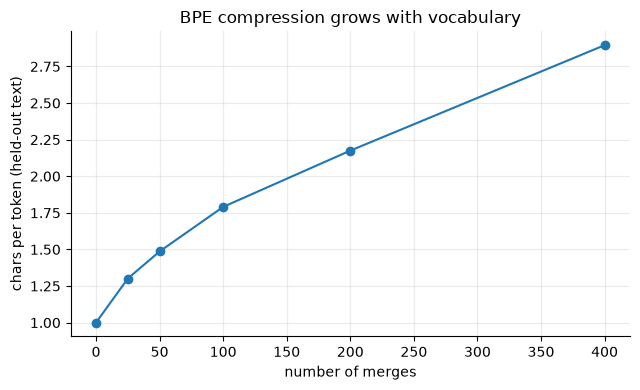

  ✅ 400 merges compress held-out text by > 2 chars/token
a rare unseen word is split into pieces, never <unk>: [' flo', 'c', 'c', 'in', 'a', 'u', 'c', 'in', 'i', 'hi', 'l', 'i', 'p', 'il', 'i', 'fi', 'c', 'ation']


In [3]:
from collections import Counter
def pretokenize(text): return re.findall(r"\s*\S+|\s+", text)                      # words with their leading whitespace
def train_bpe(text, n_merges):
    wc = Counter(pretokenize(text)); words = {w: tuple(w) for w in wc}; merges = []
    for _ in range(n_merges):
        pairs = Counter()
        for w, f in wc.items():
            sy = words[w]
            for a, b in zip(sy, sy[1:]): pairs[(a, b)] += f
        if not pairs: break
        best = max(pairs, key=pairs.get); merges.append(best); new = best[0] + best[1]
        for w in words:
            sy = words[w]; 
            if best[0] not in sy: continue
            out, i = [], 0
            while i < len(sy):
                if i < len(sy) - 1 and sy[i] == best[0] and sy[i + 1] == best[1]: out.append(new); i += 2
                else: out.append(sy[i]); i += 1
            words[w] = tuple(out)
    return merges
class BPE:
    def __init__(s, merges, base_chars): s.rank = {m: i for i, m in enumerate(merges)}; vocab = list(sorted(base_chars)) + [a + b for a, b in merges]; s.vocab = vocab; s.stoi = {t: i for i, t in enumerate(vocab)}
    def encode_word(s, w):
        sy = list(w)
        while len(sy) > 1:
            cand = [(s.rank[p], i) for i, p in enumerate(zip(sy, sy[1:])) if p in s.rank]
            if not cand: break
            _, i = min(cand); sy[i:i + 2] = [sy[i] + sy[i + 1]]
        return sy
    def encode(s, text): return [s.stoi[t] for w in pretokenize(text) for t in s.encode_word(w)]
    def decode(s, ids): return "".join(s.vocab[i] for i in ids)
base = sorted(set(train_text + val_text)); 
with timer("bpe_training"): merges = train_bpe(train_text, 400)
bpe = BPE(merges, base); print(f"base symbols {len(base)}, merges {len(merges)}, vocab {len(bpe.vocab)}"); print("first merges:", merges[:8]); print("last merges :", merges[-5:])
sample = val_docs[3]; ids = bpe.encode(sample); print(f"\nsample: {len(sample)} chars -> {len(ids)} tokens  (compression ×{len(sample)/len(ids):.2f})")
print("tokens:", [bpe.vocab[i] for i in ids[:25]])
check(bpe.decode(ids) == sample, "decode(encode(x)) == x  (lossless round trip)")
check(all(bpe.decode(bpe.encode(d)) == d for d in val_docs[:50]), "round trip holds for 50 held-out documents")
xs_m = [0, 25, 50, 100, 200, 400]; comp = []
for k in xs_m: b_ = BPE(merges[:k], base); comp.append(len(val_text) / len(b_.encode(val_text)))
plt.plot(xs_m, comp, "o-"); plt.xlabel("number of merges"); plt.ylabel("chars per token (held-out text)"); plt.title("BPE compression grows with vocabulary"); show("bpe_compression")
check(comp[-1] > 2.5 * comp[0] / 1.0 or comp[-1] > 2.0, "400 merges compress held-out text by > 2 chars/token"); METRICS["bpe_chars_per_token"] = comp[-1]
print("a rare unseen word is split into pieces, never <unk>:", [bpe.vocab[i] for i in bpe.encode(' floccinaucinihilipilification')])

## 3 · A small GPT on BPE tokens; perplexity
Pre-LN decoder-only Transformer (as in Module 14) with weight tying. We train on the BPE-encoded train split and report **validation cross-entropy and perplexity** $=e^{\text{loss}}$. Because tokens differ, loss per *token* is not comparable across tokenizers; we also report **bits per character** $=\text{loss}\cdot\text{tokens}/(\text{chars}\cdot\ln2)$ which is.

train tokens 370,726, val tokens 39,110, vocab 495


  step    0 train 65.141  val 64.008


  step  140 train 4.710  val 4.029


  step  280 train 3.166  val 3.279


  step  420 train 3.547  val 2.949


  step  560 train 2.959  val 2.778


18:18:29 | INFO | gpt_main_training took 54.63s


params 395,520 | val loss 2.643 nats/token | perplexity 14.1 | bits/char 1.317 | uniform-baseline ppl 495
18:18:29 | INFO | figure saved -> figures/gpt_train_loss.png


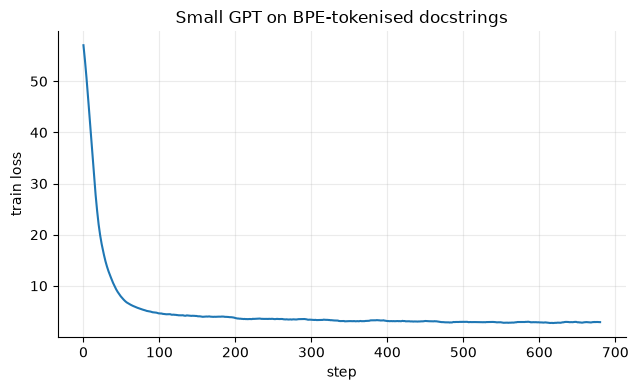

  ✅ validation perplexity is far below the uniform baseline (vocab size)


In [4]:
tr_ids = torch.tensor(bpe.encode(train_text)); va_ids = torch.tensor(bpe.encode(val_text)); V = len(bpe.vocab)
print(f"train tokens {len(tr_ids):,}, val tokens {len(va_ids):,}, vocab {V}")
class Attn(nn.Module):
    def __init__(s, d, h): super().__init__(); s.h, s.dk = h, d // h; s.qkv = nn.Linear(d, 3 * d); s.o = nn.Linear(d, d)
    def forward(s, x, cache=None):                                          # cache: dict with 'k','v' of past tokens  (B,h,Tpast,dk)
        B, T, d = x.shape; q, k, v = s.qkv(x).view(B, T, 3, s.h, s.dk).permute(2, 0, 3, 1, 4)
        if cache is not None:
            if "k" in cache: k, v = torch.cat([cache["k"], k], 2), torch.cat([cache["v"], v], 2)
            cache["k"], cache["v"] = k, v
        Tk = k.shape[2]; sc = q @ k.transpose(-1, -2) / s.dk ** .5; past = Tk - T
        mask = torch.arange(Tk)[None] > (torch.arange(T)[:, None] + past); sc = sc.masked_fill(mask, float("-inf"))     # causal w.r.t. absolute positions
        return s.o((F.softmax(sc, -1) @ v).transpose(1, 2).reshape(B, T, d))
class Block(nn.Module):
    def __init__(s, d, h): super().__init__(); s.n1, s.n2 = nn.LayerNorm(d), nn.LayerNorm(d); s.a = Attn(d, h); s.f = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
    def forward(s, x, cache=None): x = x + s.a(s.n1(x), cache); return x + s.f(s.n2(x))
class GPT(nn.Module):
    def __init__(s, V, d=96, h=4, L=3, ctx=128): super().__init__(); s.tok, s.pos = nn.Embedding(V, d), nn.Embedding(ctx, d); s.blocks = nn.ModuleList([Block(d, h) for _ in range(L)]); s.nf = nn.LayerNorm(d); s.head = nn.Linear(d, V, bias=False); s.head.weight = s.tok.weight; s.ctx = ctx
    def forward(s, idx, caches=None, start=0):
        T = idx.shape[1]; x = s.tok(idx) + s.pos(torch.arange(start, start + T))
        for i, b in enumerate(s.blocks): x = b(x, None if caches is None else caches[i])
        return s.head(s.nf(x))
def batch(ids, B, L, g=None): ix = torch.randint(0, len(ids) - L - 1, (B,), generator=g); return torch.stack([ids[i:i + L] for i in ix]), torch.stack([ids[i + 1:i + L + 1] for i in ix])
@torch.no_grad()
def val_loss(m, n=40, L=64):
    m.eval(); g = torch.Generator().manual_seed(0); ls = []
    for _ in range(n): x, y = batch(va_ids, 16, L, g); ls.append(F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1)).item())
    return float(np.mean(ls))
def train_gpt(d, L, steps, seed=0, B=32, ctx=64, lr=3e-3, log_every=0):
    torch.manual_seed(seed); m = GPT(V, d, 4, L, 128); o = torch.optim.AdamW(m.parameters(), lr, weight_decay=.01); sch = torch.optim.lr_scheduler.OneCycleLR(o, lr, total_steps=steps, pct_start=.1); hist = []
    for it in range(steps):
        m.train(); x, y = batch(tr_ids, B, ctx); loss = F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1)); o.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); o.step(); sch.step(); hist.append(loss.item())
        if log_every and it % log_every == 0: print(f"  step {it:4d} train {loss.item():.3f}  val {val_loss(m, 10):.3f}")
    return m, hist
with timer("gpt_main_training"): gpt, hist = train_gpt(96, 3, 700, log_every=140)
vl = val_loss(gpt); chars_per_tok = len(val_text) / len(va_ids); bpc = vl * len(va_ids) / len(val_text) / np.log(2)
print(f"params {count_params(gpt):,} | val loss {vl:.3f} nats/token | perplexity {np.exp(vl):.1f} | bits/char {bpc:.3f} | uniform-baseline ppl {V}")
plt.plot(np.convolve(hist, np.ones(20) / 20, "valid")); plt.xlabel("step"); plt.ylabel("train loss"); plt.title("Small GPT on BPE-tokenised docstrings"); show("gpt_train_loss")
check(np.exp(vl) < V / 4, "validation perplexity is far below the uniform baseline (vocab size)"); METRICS.update(gpt_val_loss=vl, gpt_ppl=float(np.exp(vl)), gpt_bits_per_char=float(bpc), gpt_params=count_params(gpt))

## 4 · A mini scaling law
Kaplan/Hoffmann et al. found test loss follows a power law in parameters, $L(N)\approx(N_c/N)^{\alpha}+L_\infty$. We train 4 model widths with an identical (small) data/compute budget and fit a straight line in log–log space for the *reducible* part. At this tiny scale the exponent is only indicative, but the **monotone improvement with size** is the robust phenomenon.

d= 16 L=1: non-embedding params    3,312  val loss 5.390


d= 32 L=2: non-embedding params   25,472  val loss 4.155


d= 64 L=2: non-embedding params  100,096  val loss 3.606


d=128 L=3: non-embedding params  595,072  val loss 2.620
18:19:59 | INFO | scaling_sweep took 90.07s


18:20:00 | INFO | figure saved -> figures/scaling_law.png


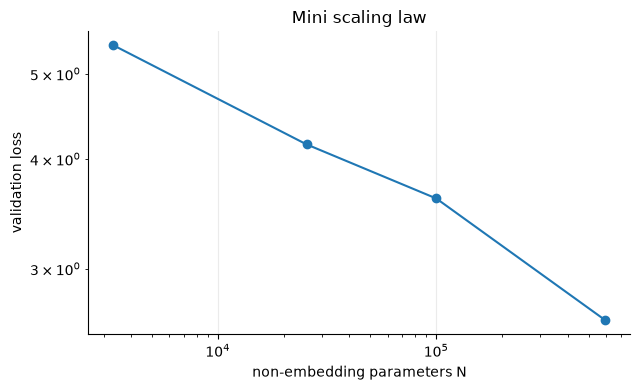

log-log slope of loss vs N: -0.136
  ✅ validation loss decreases monotonically with model size
  ✅ negative log-log slope (power-law-like trend)


In [5]:
sizes = [(16, 1), (32, 2), (64, 2), (128, 3)]; pts = []
with timer("scaling_sweep"):
    for d, L in sizes:
        m, h = train_gpt(d, L, 500, seed=1); v = val_loss(m); N = sum(p.numel() for n_, p in m.named_parameters() if "tok" not in n_ and "pos" not in n_ and "head" not in n_); pts.append((N, v)); print(f"d={d:3d} L={L}: non-embedding params {N:8,d}  val loss {v:.3f}")
Ns, Vs = np.array(pts).T; plt.loglog(Ns, Vs, "o-"); plt.xlabel("non-embedding parameters N"); plt.ylabel("validation loss"); plt.title("Mini scaling law"); show("scaling_law")
slope = np.polyfit(np.log(Ns), np.log(Vs), 1)[0]; print(f"log-log slope of loss vs N: {slope:.3f}")
check(all(Vs[i] > Vs[i + 1] for i in range(len(Vs) - 1)), "validation loss decreases monotonically with model size"); check(slope < 0, "negative log-log slope (power-law-like trend)"); METRICS["scaling"] = dict(N=Ns, val=Vs, slope=slope)

## 5 · The KV cache
Autoregressive generation naively recomputes attention for *all* previous tokens at every step: $O(T^2)$ per step. Keys and values of past tokens never change, so we **cache** them and compute only the new token's $q,k,v$: $O(T)$ per step. Our `Attn` already supports it. We prove equivalence (logits identical) and measure the speed-up.

In [6]:
import time
gpt.eval(); prompt = torch.tensor([bpe.encode("The function returns")]); n_new = 60
@torch.no_grad()
def gen_nocache(m, ids, n):
    for _ in range(n): ids = torch.cat([ids, m(ids[:, -m.ctx:])[:, -1].argmax(-1, keepdim=True)], 1)
    return ids
@torch.no_grad()
def gen_cache(m, ids, n):
    caches = [dict() for _ in m.blocks]; lg = m(ids, caches, 0); out = ids
    for i in range(n): nxt = lg[:, -1].argmax(-1, keepdim=True); out = torch.cat([out, nxt], 1); lg = m(nxt, caches, out.shape[1] - 1)
    return out
t0 = time.perf_counter(); a = gen_nocache(gpt, prompt, n_new); t1 = time.perf_counter(); b = gen_cache(gpt, prompt, n_new); t2 = time.perf_counter()
print(f"no cache: {t1-t0:.3f}s   with KV cache: {t2-t1:.3f}s   speed-up ×{(t1-t0)/(t2-t1):.1f}"); print("generated:", repr(bpe.decode(b[0].tolist())[:140]))
check(torch.equal(a, b), "greedy decoding with and without the KV cache yields IDENTICAL tokens")
with torch.no_grad():
    full = gpt(b[:, :40]); caches = [dict() for _ in gpt.blocks]; inc = torch.cat([gpt(b[:, :30], caches, 0), *[gpt(b[:, i:i + 1], caches, i) for i in range(30, 40)]], 1)
check(torch.allclose(full, inc, atol=1e-4), "incremental logits == full-forward logits (max diff %.1e)" % (full - inc).abs().max())
check(t2 - t1 < t1 - t0, "the KV cache makes decoding faster"); METRICS["kv_cache_speedup"] = (t1 - t0) / (t2 - t1)
cfg = dict(layers=32, kv_heads=32, d_head=128); per_tok = 2 * cfg["layers"] * cfg["kv_heads"] * cfg["d_head"] * 2; print(f"7B-class fp16 KV cache: {per_tok/2**20:.2f} MiB/token -> {per_tok*4096/2**30:.1f} GiB at 4k context")

no cache: 0.098s   with KV cache: 0.060s   speed-up ×1.6
generated: 'The function returns is ad, the signcess.\n\nThe opencessert.\n\nThe res a shomenert is a testamatormenting the res a temmined.\n\nThe re'
  ✅ greedy decoding with and without the KV cache yields IDENTICAL tokens
  ✅ incremental logits == full-forward logits (max diff 6.9e-06)
  ✅ the KV cache makes decoding faster
7B-class fp16 KV cache: 0.50 MiB/token -> 2.0 GiB at 4k context


## 6 · Decoding strategies
Given next-token logits $z$: **greedy** (argmax); **temperature** $T$ (sample from softmax$(z/T)$); **top-$k$** (keep the $k$ most likely tokens); **top-$p$ / nucleus** (keep the smallest set whose cumulative probability $\ge p$). We implement the filters, *test them on a known distribution*, then compare generated text on diversity (distinct-2 = fraction of unique bigrams) and repetition.

  ✅ top-k=2 keeps exactly 2 tokens
  ✅ top-p=0.8 keeps the minimal prefix with mass ≥ 0.8 (here 3 tokens: .5+.25+.15=.9)
  ✅ T→0 is greedy, T→∞ uniform


greedy           distinct-2 0.810   sample: 'Return the sicess.\n\nBogs a\nccesserstemaget is a t'


T=0.7            distinct-2 0.934   sample: 'Return the otherI.\n\n\nint([x]) -> integer\nint(x,\nint(x, base=10) -> integer\n\nConvert a number or string to an i'


T=1.0            distinct-2 0.986   sample: "Return the thand Trueue`` to keesatext-pend='cuff plated"


T=1.0 top-k 10   distinct-2 0.932   sample: 'Return the otherI.tatortruesatext and a tast\nche plated'


T=1.0 top-p .9   distinct-2 0.994   sample: "Return the thand Trueue`` to keesatext-pend='chenameted"


T=1.5            distinct-2 0.988   sample: 'Return thees l or\nint(x, base=10) -> integer\n\nConvert other de not a integer end(bytes_c) -> strted'
  ✅ greedy decoding is more repetitive than sampling at T=1
  ✅ higher temperature -> more diverse
18:20:04 | INFO | figure saved -> figures/decoding_diversity.png


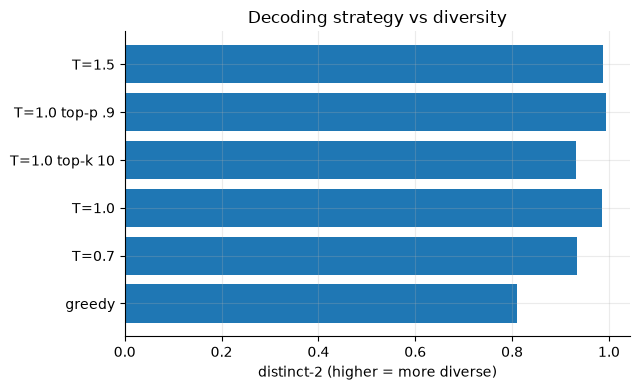

In [7]:
def filter_logits(z, top_k=0, top_p=1.0):
    z = z.clone()
    if top_k: kth = torch.topk(z, top_k).values[..., -1, None]; z[z < kth] = float("-inf")
    if top_p < 1:
        sz, si = torch.sort(z, descending=True); cp = F.softmax(sz, -1).cumsum(-1); remove = cp - F.softmax(sz, -1) >= top_p; sz[remove] = float("-inf"); z = torch.full_like(z, float("-inf")).scatter(-1, si, sz)
    return z
p = torch.tensor([.5, .25, .15, .06, .04]); z = p.log()
kept_k = (filter_logits(z, top_k=2) > -1e9).sum().item(); kept_p = (filter_logits(z, top_p=.8) > -1e9).sum().item()
check(kept_k == 2, "top-k=2 keeps exactly 2 tokens"); check(kept_p == 3 and p[:kept_p].sum() >= .8 and p[:kept_p - 1].sum() < .8, "top-p=0.8 keeps the minimal prefix with mass ≥ 0.8 (here 3 tokens: .5+.25+.15=.9)")
sm = lambda T: F.softmax(z / T, -1); check(sm(.1).max() > .99 and sm(100).max() < .21, "T→0 is greedy, T→∞ uniform")
@torch.no_grad()
def sample_text(m, prompt, n=80, T=1.0, top_k=0, top_p=1.0, seed=0):
    g = torch.Generator().manual_seed(seed); ids = torch.tensor([bpe.encode(prompt)]); caches = [dict() for _ in m.blocks]; lg = m(ids, caches, 0)
    for i in range(n):
        z = filter_logits(lg[0, -1] / max(T, 1e-6), top_k, top_p); nxt = torch.multinomial(F.softmax(z, -1), 1, generator=g) if T > 0 else z.argmax(-1, keepdim=True); ids = torch.cat([ids, nxt[None]], 1); lg = m(nxt[None], caches, ids.shape[1] - 1)
    return ids[0].tolist()
def distinct2(ids): bg = list(zip(ids, ids[1:])); return len(set(bg)) / len(bg)
cfgs = {"greedy": dict(T=0), "T=0.7": dict(T=.7), "T=1.0": dict(T=1.0), "T=1.0 top-k 10": dict(T=1.0, top_k=10), "T=1.0 top-p .9": dict(T=1.0, top_p=.9), "T=1.5": dict(T=1.5)}; stats = {}
for nm, kw in cfgs.items():
    ds = [distinct2(sample_text(gpt, "Return the", 120, seed=s, **kw)) for s in range(4)]; stats[nm] = np.mean(ds); print(f"{nm:16s} distinct-2 {stats[nm]:.3f}   sample: {bpe.decode(sample_text(gpt, 'Return the', 25, seed=0, **kw))[:110]!r}")
check(stats["greedy"] < stats["T=1.0"] or stats["greedy"] < .9, "greedy decoding is more repetitive than sampling at T=1"); check(stats["T=1.5"] >= stats["T=0.7"], "higher temperature -> more diverse")
plt.barh(list(stats), list(stats.values())); plt.xlabel("distinct-2 (higher = more diverse)"); plt.title("Decoding strategy vs diversity"); show("decoding_diversity"); METRICS["distinct2"] = stats

## 7 · Alignment: reward model and DPO on a toy preference problem
RLHF pipeline: (1) supervised fine-tune; (2) fit a **reward model** from human preference pairs with the **Bradley–Terry** model $P(y_w\succ y_l)=\sigma(r(y_w)-r(y_l))$; (3) optimise the policy against the reward with a KL penalty to the reference, $\max_\pi\mathbb E_\pi[r]-\beta D_{KL}(\pi\|\pi_{ref})$. **DPO** shows the optimum is $\pi^*\propto\pi_{ref}e^{r/\beta}$, so the reward is $r=\beta\log\frac{\pi}{\pi_{ref}}$ and one can train directly on preferences:
$$\mathcal L_{DPO}=-\log\sigma\Big(\beta\big[\log\tfrac{\pi(y_w)}{\pi_{ref}(y_w)}-\log\tfrac{\pi(y_l)}{\pi_{ref}(y_l)}\big]\Big).$$
Toy world: one prompt, $K=6$ possible responses with a hidden true reward. We (a) recover the reward from noisy pairwise preferences, (b) train a tabular policy with DPO, (c) verify against the closed-form optimum and show the effect of $\beta$.

true reward : [-1.5 -0.9 -0.3  0.3  0.9  1.5]
learned (centred): [-1.39 -0.79 -0.28  0.25  0.72  1.49]
  ✅ reward model recovers the correct ranking of all 6 responses
  ✅ …and the reward values up to a constant shift
  ✅ at π = π_ref the DPO loss is exactly log 2


β= 0.05: E_π[r] 3.00   KL(π‖π_ref) 3.38   top response prob 1.00


β=  0.2: E_π[r] 2.97   KL(π‖π_ref) 3.18   top response prob 0.96


β=  1.0: E_π[r] 1.60   KL(π‖π_ref) 0.43   top response prob 0.21


β=  5.0: E_π[r] 0.87   KL(π‖π_ref) 0.01   top response prob 0.36
reference policy E[r] = 0.74
  ✅ DPO improves expected true reward for every β
  ✅ small β: larger reward gain but larger KL from the reference (β is a trust-region knob)


18:20:07 | INFO | figure saved -> figures/dpo.png


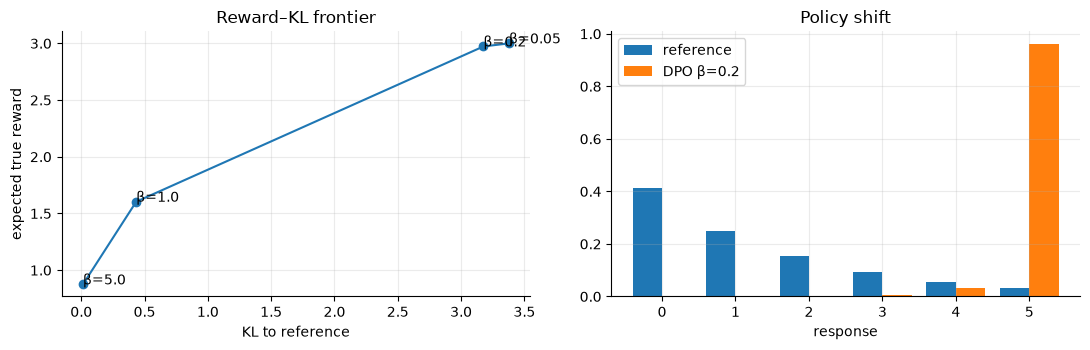

note: with finite noisy data the DPO policy approximates (not exactly equals) the closed-form optimum π* ∝ π_ref·exp(r/β):
  β=0.05: max |π−π*| = 0.000
  β=0.2: max |π−π*| = 0.043
  β=1.0: max |π−π*| = 0.031
  β=5.0: max |π−π*| = 0.004


[None, None, None, None]

In [8]:
K = 6; r_true = torch.tensor([0., 1., 2., 3., 4., 5.]) * .6; rng = np.random.default_rng(0)
def sample_pairs(n):
    out = []
    for _ in range(n):
        i, j = rng.choice(K, 2, replace=False); pw = torch.sigmoid(r_true[i] - r_true[j]).item(); out.append((i, j) if rng.random() < pw else (j, i))     # (winner, loser) drawn from Bradley–Terry
    return out
pairs = sample_pairs(2000); w, l = torch.tensor([p[0] for p in pairs]), torch.tensor([p[1] for p in pairs])
# (a) reward model by maximum likelihood
r_hat = torch.zeros(K, requires_grad=True); o = torch.optim.Adam([r_hat], .05)
for _ in range(300): loss = -F.logsigmoid(r_hat[w] - r_hat[l]).mean(); o.zero_grad(); loss.backward(); o.step()
rh = (r_hat - r_hat.mean()).detach(); rt = r_true - r_true.mean(); print("true reward :", rt.numpy().round(2)); print("learned (centred):", rh.numpy().round(2))
check(torch.equal(rh.argsort(), rt.argsort()), "reward model recovers the correct ranking of all 6 responses"); check((rh - rt).abs().max() < .35, "…and the reward values up to a constant shift")
# (b) DPO against a non-uniform reference policy
ref_logits = torch.tensor([1.5, 1.0, .5, 0., -.5, -1.]); logp_ref = F.log_softmax(ref_logits, 0)
def dpo_loss(logits, beta): lp = F.log_softmax(logits, 0); return -F.logsigmoid(beta * ((lp[w] - logp_ref[w]) - (lp[l] - logp_ref[l]))).mean()
def train_dpo(beta, steps=1500): th = ref_logits.clone().requires_grad_(); o = torch.optim.Adam([th], .02); [(o.zero_grad(), dpo_loss(th, beta).backward(), o.step()) for _ in range(steps)]; return F.softmax(th.detach(), 0)
check(abs(dpo_loss(ref_logits, .1).item() - np.log(2.0)) < 1e-5, "at π = π_ref the DPO loss is exactly log 2")
res = {}
for beta in [.05, .2, 1.0, 5.0]:
    pi = train_dpo(beta); er = (pi * r_true).sum().item(); kl = (pi * (pi.log() - logp_ref)).sum().item(); star = F.softmax(logp_ref + r_true / beta, 0); res[beta] = (er, kl, pi, star)
    print(f"β={beta:5}: E_π[r] {er:.2f}   KL(π‖π_ref) {kl:.2f}   top response prob {pi.max():.2f}")
er_ref = (F.softmax(ref_logits, 0) * r_true).sum().item(); print(f"reference policy E[r] = {er_ref:.2f}")
check(all(v[0] > er_ref for v in res.values()), "DPO improves expected true reward for every β"); check(res[.05][1] > res[5.0][1] and res[.05][0] > res[5.0][0], "small β: larger reward gain but larger KL from the reference (β is a trust-region knob)")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6)); ax[0].plot([res[b][1] for b in res], [res[b][0] for b in res], "o-"); [ax[0].annotate(f"β={b}", (res[b][1], res[b][0])) for b in res]; ax[0].set_xlabel("KL to reference"); ax[0].set_ylabel("expected true reward"); ax[0].set_title("Reward–KL frontier")
ax[1].bar(np.arange(K) - .2, F.softmax(ref_logits, 0), .4, label="reference"); ax[1].bar(np.arange(K) + .2, res[.2][2], .4, label="DPO β=0.2"); ax[1].set_xlabel("response"); ax[1].legend(); ax[1].set_title("Policy shift"); show("dpo"); METRICS["dpo"] = {str(b): dict(reward=v[0], kl=v[1]) for b, v in res.items()}
print("note: with finite noisy data the DPO policy approximates (not exactly equals) the closed-form optimum π* ∝ π_ref·exp(r/β):"); [print(f"  β={b}: max |π−π*| = {(res[b][2] - res[b][3]).abs().max():.3f}") for b in res]

## 8 · Retrieval-augmented generation (RAG) — the retrieval half
RAG gives an LLM *non-parametric memory*: retrieve the most relevant documents for a query and place them in the prompt. We build a **TF-IDF** retriever over the docstring documents (index = the *rest* of every docstring, i.e. without its first sentence; query = that first summary sentence, so there is no verbatim leakage). Metrics: **recall@k** (is the source document in the top-$k$?) and mean reciprocal rank. We compare with random retrieval and then assemble a context-limited prompt.

2,667 indexed docs, 300 queries -> recall@1 0.16 @5 0.32 @10 0.37 @50 0.48  MRR 0.24   (random recall@5 ≈ 0.0019)
  ✅ TF-IDF retrieval is vastly better than random
  ✅ no trivial leakage: recall@1 is below 100%

QUERY: int([x]) -> integer
int(x, base=10) -> integer

Convert a number or string to an integer, or return 0 if no arguments
ar
  rank 1 (score 0.40): LIST
  rank 2 (score 0.40): GLOBAL
  rank 3 (score 0.40): EMPTY_LIST

assembled prompt uses 166 context tokens (budget 250) with 1 documents
  ✅ prompt assembly respects the context-token budget


18:20:08 | INFO | figure saved -> figures/rag_recall.png


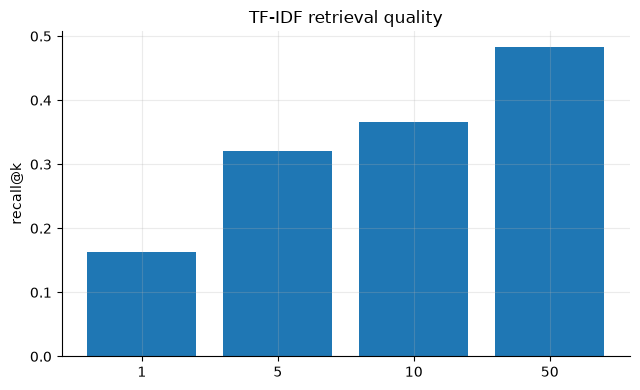

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
corpus = docs
body = lambda d: d.split("\n", 1)[1].strip()
first_sentence = lambda d: re.split(r"(?<=[.!?])\s", body(d))[0]
rest = lambda d: body(d)[len(first_sentence(d)):].strip()                       # the docstring WITHOUT its first sentence (no leakage of the query)
vec = TfidfVectorizer(sublinear_tf=True, stop_words="english", ngram_range=(1, 2)); M = vec.fit_transform([rest(d) or d.split("\n", 1)[0] for d in corpus])
qs = [(i, first_sentence(corpus[i])) for i in range(0, len(corpus), 3) if len(rest(corpus[i])) > 60][:300]       # query = summary line, target = the document it summarises
Q = vec.transform([q for _, q in qs]); S = (Q @ M.T).toarray()
ranks = np.array([(S[r] > S[r, i]).sum() for r, (i, _) in enumerate(qs)])       # 0 = retrieved at rank 1
rec = {k: float((ranks < k).mean()) for k in [1, 5, 10, 50]}; mrr = float((1 / (ranks + 1)).mean()); rand_rec5 = 5 / len(corpus)
print(f"{len(corpus):,} indexed docs, {len(qs)} queries -> recall@1 {rec[1]:.2f} @5 {rec[5]:.2f} @10 {rec[10]:.2f} @50 {rec[50]:.2f}  MRR {mrr:.2f}   (random recall@5 ≈ {rand_rec5:.4f})")
check(rec[5] > 50 * rand_rec5, "TF-IDF retrieval is vastly better than random"); check(rec[1] < 0.99, "no trivial leakage: recall@1 is below 100%"); METRICS["rag"] = dict(recall=rec, mrr=mrr)
qi = 7; top = np.argsort(-S[qi])[:3]; print("\nQUERY:", qs[qi][1][:120]); [print(f"  rank {j+1} (score {S[qi, t]:.2f}): {corpus[t].splitlines()[0]}") for j, t in enumerate(top)]
def build_prompt(query, idxs, budget_tokens=250):
    ctx, used = [], 0
    for t in idxs:
        n = len(bpe.encode(corpus[t]))
        if used + n > budget_tokens: break
        ctx.append(f"[doc {len(ctx)+1}] {corpus[t]}"); used += n
    return "\n\n".join(ctx) + f"\n\nQuestion: {query}\nAnswer:", used
prompt, used = build_prompt(qs[qi][1], np.argsort(-S[qi])[:10]); print(f"\nassembled prompt uses {used} context tokens (budget 250) with {prompt.count('[doc')} documents")
check(used <= 250, "prompt assembly respects the context-token budget")
plt.bar([str(k) for k in rec], list(rec.values())); plt.ylabel("recall@k"); plt.title("TF-IDF retrieval quality"); show("rag_recall")

## 9 · Multimodal: ViT-style patch tokens
A Vision Transformer turns an image into a **sequence of tokens**: cut into $P\times P$ patches, flatten, linearly project. This is identical to a strided convolution with kernel = stride = $P$. Once images are token sequences, a multimodal LLM just *concatenates* projected image tokens with text tokens. We verify the conv/linear equivalence and the shapes.

In [10]:
from sklearn.datasets import load_digits
img = torch.tensor(load_digits().images[:4] / 16., dtype=torch.float32)[:, None]; P, d = 2, 16                      # (4,1,8,8): 16 patches of 2x2
patches = img.unfold(2, P, P).unfold(3, P, P).permute(0, 2, 3, 1, 4, 5).reshape(4, -1, P * P)                   # (B, 16, 4)
lin = nn.Linear(P * P, d); conv = nn.Conv2d(1, d, P, stride=P); conv.weight.data = lin.weight.data.view(d, 1, P, P).clone(); conv.bias.data = lin.bias.data.clone()
tok_lin = lin(patches); tok_conv = conv(img).flatten(2).transpose(1, 2)
print("patch tokens:", tuple(tok_lin.shape), "= (batch, #patches, d_model)")
check(patches.shape == (4, 16, 4) and tok_lin.shape == (4, 16, 16), "8×8 image / 2×2 patches -> 16 tokens")
check(torch.allclose(tok_lin, tok_conv, atol=1e-6), "linear projection of flattened patches == strided convolution")
text_tok = torch.randn(4, 5, d); seq = torch.cat([tok_conv, text_tok], 1); check(seq.shape == (4, 21, 16), "multimodal sequence = [16 image tokens ; 5 text tokens] fed to one Transformer")
n_tok_224 = (224 // 16) ** 2; print(f"a 224×224 image with 16×16 patches -> {n_tok_224} tokens; attention cost ∝ {n_tok_224}² = {n_tok_224**2:,}")

patch tokens: (4, 16, 16) = (batch, #patches, d_model)
  ✅ 8×8 image / 2×2 patches -> 16 tokens
  ✅ linear projection of flattened patches == strided convolution
  ✅ multimodal sequence = [16 image tokens ; 5 text tokens] fed to one Transformer
a 224×224 image with 16×16 patches -> 196 tokens; attention cost ∝ 196² = 38,416


In [11]:
save_metrics("23", METRICS)
log.info('notebook 23 finished OK')

18:20:08 | INFO | metrics saved -> metrics.json


18:20:08 | INFO | notebook 23 finished OK


## Wrap-up

## Exercises (do these next)

1. Train the BPE with 1,000 merges and compare chars/token and GPT bits/char at equal parameter count.
2. Implement beam search with the KV cache (cache per beam) and compare with greedy.
3. Replace TF-IDF by a dense retriever (e.g. average the trained GPT's token embeddings) and compare recall@k.

## Where to read more

- Wiki chapter: [Module 23](https://github.com/anuxlab/deep-learning-systems/wiki/Module-23) (derivations, worked example, Q&A).
- Sennrich et al. (2016) BPE; Radford et al. (2019) GPT-2; Kaplan et al. (2020) & Hoffmann et al. (2022) scaling laws; Holtzman et al. (2020) nucleus sampling; Christiano et al. (2017); Rafailov et al. (2023) DPO; Lewis et al. (2020) RAG; Dosovitskiy et al. (2021) ViT.